# Replicating Becker on our Kalshi sample

Becker finds systematic mispricing across Kalshi, especially among longshots and between makers and takers. Here we reproduce his main descriptive checks on **our recent-year CSV subset**. The separate [extension notebook](main.ipynb) asks whether finer contract groups help predict mispricing.

This is a **sample-restricted replication**, not an exact reproduction of the paper's numbers. Becker studies June 2021–November 2025; our files cover November 25, 2024–November 25, 2025. In this notebook, we do not attempt to reproduce his earlier time trends. We use all master CSVs here, without model training or train/test splits.

**Plan:** check the sample → measure calibration → compare YES/NO and maker/taker positions → check uncertainty → decompose taker mispricing. Figures and tables are also saved in `output/replication/`.

## 1. Set up the replication

The colors match `main.ipynb`. DuckDB reads the large trade CSV without loading every trade into pandas. The analysis below is contained here; the only imported research helper is Becker's existing rule-based category lookup in `src/analysis/kalshi/util/categories.py`.

In [15]:
from __future__ import annotations

import hashlib
import json
import time
from importlib.metadata import version
from pathlib import Path
from runpy import run_path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import norm

ROOT = next(
    (path for path in [Path.cwd(), *Path.cwd().parents] if (path / "data/kalshi_recent_year_csv").is_dir()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Run from the repository or one of its subdirectories.")
DATA = ROOT / "data/kalshi_recent_year_csv"
OUTPUT = ROOT / "output/replication"
OUTPUT.mkdir(parents=True, exist_ok=True)
INPUTS = [DATA / "master/markets.csv", DATA / "master/trades.csv", DATA / "manifest.json"]
for path in INPUTS:
    if not path.is_file():
        raise FileNotFoundError(path)
CATEGORY_SOURCE = ROOT / "src/analysis/kalshi/util/categories.py"
get_group = run_path(str(CATEGORY_SOURCE))["get_group"]
source_manifest = json.loads((DATA / "manifest.json").read_text())
started = time.time()
(OUTPUT / "run_manifest.json").write_text(json.dumps({"completed": False}) + "\n")

PALETTE = {
    "navy": "#18163F",
    "mint": "#D9FBEA",
    "mint_dark": "#3D9F83",
    "lavender": "#BFC5FF",
    "lavender_dark": "#858DD5",
    "lavender_light": "#DFE3FF",
    "gray_light": "#F2F2F2",
    "gray": "#C7C8D1",
    "gray_dark": "#777786",
}
ROLE_COLORS = {"Maker": PALETTE["mint_dark"], "Taker": PALETTE["navy"]}
DIRECTION_COLORS = {"yes": PALETTE["lavender_dark"], "no": PALETTE["mint_dark"]}
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "font.size": 10,
        "axes.titleweight": "bold",
        "text.color": PALETTE["navy"],
        "axes.labelcolor": PALETTE["navy"],
        "axes.titlecolor": PALETTE["navy"],
        "axes.edgecolor": PALETTE["navy"],
        "xtick.color": PALETTE["navy"],
        "ytick.color": PALETTE["navy"],
        "axes.spines.top": False,
        "axes.spines.right": False,
        "lines.linewidth": 2,
        "legend.facecolor": "white",
        "legend.edgecolor": PALETTE["gray"],
    }
)


def show_figure(name: str) -> None:
    """Show the chart and save the same figure for later use."""
    plt.gcf().tight_layout()
    plt.gcf().savefig(OUTPUT / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()


def save_table(frame: pd.DataFrame, name: str) -> None:
    frame.to_csv(OUTPUT / f"{name}.csv", index=False)
    display(frame)

## 2. Which trades belong in the analysis?

Following Becker, keep finalized markets with a YES/NO outcome and at least **$100 in observed notional volume**. One matched YES/NO unit costs $1 in total, so notional volume is the sum of contract units traded. Our threshold uses this CSV window, rather than full market histories.

We also screen malformed trades: missing IDs or timestamps, nonpositive units, invalid sides, prices outside 1–99¢, or YES/NO prices that do not sum to 100¢. Duplicate trade IDs or market tickers stop the notebook instead of being silently counted twice. We do **not** apply the extension's structural or NLP eligibility screens.

To save memory, identical executions within each market, price, taker side, and quarter are counted together. Keeping their execution counts and total units preserves the statistics below exactly.

In [16]:
con = duckdb.connect()
con.execute("SET threads = 4")
con.execute("SET memory_limit = '3GB'")
con.execute("SET TimeZone = 'America/New_York'")
con.execute("SET temp_directory = ?", [str(OUTPUT / "duckdb_temp")])
con.read_csv(str(INPUTS[0]), all_varchar=True).create_view("markets")
con.read_csv(str(INPUTS[1]), all_varchar=True).create_view("trade_source")
con.execute(
    """
    CREATE VIEW raw_trades AS
    SELECT trade_id, ticker, taker_side,
           try_cast(count AS BIGINT) AS units,
           try_cast(yes_price AS INTEGER) AS yes_price,
           try_cast(no_price AS INTEGER) AS no_price,
           try_cast(created_time AS TIMESTAMPTZ) AS trade_time
    FROM trade_source
    """
)
con.execute(
    """
    CREATE VIEW checked_trades AS
    SELECT *, coalesce(
        trade_id IS NOT NULL AND trim(trade_id) != ''
        AND ticker IS NOT NULL AND trim(ticker) != ''
        AND units > 0 AND taker_side IN ('yes', 'no')
        AND yes_price BETWEEN 1 AND 99 AND no_price BETWEEN 1 AND 99
        AND yes_price + no_price = 100 AND trade_time IS NOT NULL,
        false
    ) AS valid
    FROM raw_trades
    """
)
trade_audit = con.sql(
    """
    SELECT count(*) AS raw_trades,
           count(DISTINCT trade_id) AS unique_trade_ids,
           count(*) FILTER (WHERE NOT valid) AS invalid_trades,
           min(trade_time) AS first_trade, max(trade_time) AS last_trade
    FROM checked_trades
    """
).df()
market_audit = con.sql("SELECT count(*) AS raw_markets, count(DISTINCT ticker) AS unique_tickers FROM markets").df()
assert trade_audit.raw_trades.iloc[0] == trade_audit.unique_trade_ids.iloc[0], "Check duplicate/missing trade IDs."
assert market_audit.raw_markets.iloc[0] == market_audit.unique_tickers.iloc[0], "Check duplicate/missing market IDs."

con.execute(
    """
    CREATE TEMP TABLE trade_cells AS
    SELECT ticker, yes_price, taker_side,
           date_trunc('quarter', trade_time)::DATE AS quarter,
           count(*)::BIGINT AS n, sum(units)::DOUBLE AS units
    FROM checked_trades
    WHERE valid
    GROUP BY ticker, yes_price, taker_side, quarter
    """
)
con.execute(
    """
    CREATE TEMP TABLE eligible_markets AS
    SELECT m.ticker,
           coalesce(nullif(trim(m.event_ticker), ''), m.ticker) AS event_id,
           regexp_extract(coalesce(m.event_ticker, m.ticker), '^([A-Z0-9]+)', 1) AS series,
           m.result, sum(t.units) AS notional_usd
    FROM markets m
    JOIN trade_cells t ON m.ticker = t.ticker
    WHERE m.status = 'finalized' AND m.result IN ('yes', 'no')
    GROUP BY m.ticker, event_id, series, m.result
    HAVING sum(t.units) >= 100
    """
)
series = con.sql("SELECT DISTINCT series FROM eligible_markets").df()
series["category"] = series.series.map(get_group)
con.register("category_lookup", series)

population = con.sql(
    """
    SELECT count(DISTINCT m.ticker) AS retained_markets,
           count(DISTINCT m.event_id) AS retained_events,
           sum(t.n)::BIGINT AS retained_trades,
           sum(t.units) AS retained_notional_usd
    FROM eligible_markets m JOIN trade_cells t USING (ticker)
    """
).df()
save_table(trade_audit, "trade_audit")
save_table(market_audit, "market_audit")
save_table(population, "population")

,raw_trades,unique_trade_ids,invalid_trades,first_trade,last_trade
0,65017902,65017902,267291,2024-11-25 17:00:20.160313-05:00,2025-11-25 17:00:15.194245-05:00


,raw_markets,unique_tickers
0,529307,529307


,retained_markets,retained_events,retained_trades,retained_notional_usd
0,351452,100945,60451460,1.515540e+10


### Start with the sample, before looking for a pattern

The first bars show how much data remains. The quarterly chart uses **retained** notional volume. The first and last quarters are incomplete, so their shorter bars should not be interpreted as declines in activity. This corresponds to Becker's volume overview (Figure 1), on our narrower sample.

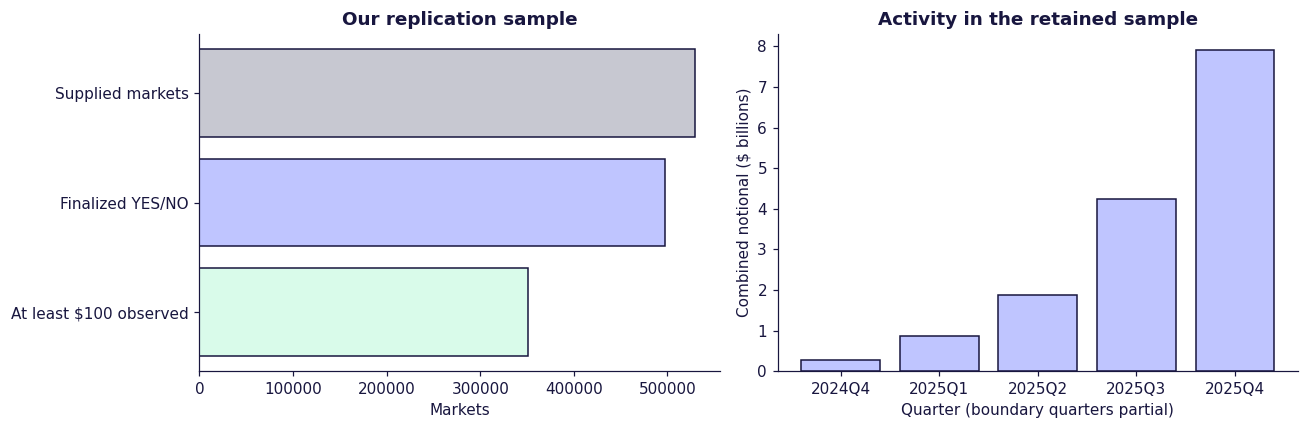

In [17]:
resolved_markets = con.sql(
    "SELECT count(*) FROM markets WHERE status = 'finalized' AND result IN ('yes', 'no')"
).fetchone()[0]
attrition = pd.DataFrame(
    {
        "stage": ["Supplied markets", "Finalized YES/NO", "At least $100 observed"],
        "markets": [int(market_audit.raw_markets.iloc[0]), resolved_markets, int(population.retained_markets.iloc[0])],
    }
)
quarterly_volume = con.sql(
    """
    SELECT quarter, sum(t.units) AS notional_usd
    FROM trade_cells t JOIN eligible_markets m USING (ticker)
    GROUP BY quarter ORDER BY quarter
    """
).df()
quarter_labels = quarterly_volume.quarter.dt.to_period("Q").astype(str)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].barh(
    attrition.stage,
    attrition.markets,
    color=[PALETTE["gray"], PALETTE["lavender"], PALETTE["mint"]],
    edgecolor=PALETTE["navy"],
)
axes[0].invert_yaxis()
axes[0].set(title="Our replication sample", xlabel="Markets")
axes[1].bar(quarter_labels, quarterly_volume.notional_usd / 1e9, color=PALETTE["lavender"], edgecolor=PALETTE["navy"])
axes[1].set(
    title="Activity in the retained sample",
    xlabel="Quarter (boundary quarters partial)",
    ylabel="Combined notional ($ billions)",
)
show_figure("01_sample_and_volume")
attrition.to_csv(OUTPUT / "market_attrition.csv", index=False)
quarterly_volume.to_csv(OUTPUT / "quarterly_volume.csv", index=False)

## 3. Turn each trade into two positions

A trade has a taker (the incoming order) and a maker (the resting counterparty). If the taker buys YES for 20¢, the maker takes NO for 80¢. Exactly one position pays $1. We compare positions at their **own purchase price**, including NO positions.

We keep Becker's two measures separate:

- **Mispricing (Equation 1):** outcome minus price / 100. Reported in **percentage points (pp)**. At 5¢, a 4% win rate means −1 pp of mispricing.
- **Gross return on capital, or ROI (Equation 2):** `(100 × outcome − price) / price`. Reported in **percent**. That same 5¢ position has a −20% average return.

Unless labeled otherwise, averages give each execution-position equal weight, as in the paper's per-trade analysis. Units determine volume and capital shares, not the calibration curves. Fees are excluded. Maker and taker **mispricing** must cancel across all trades; their percentage ROIs need not cancel because they invest different amounts.

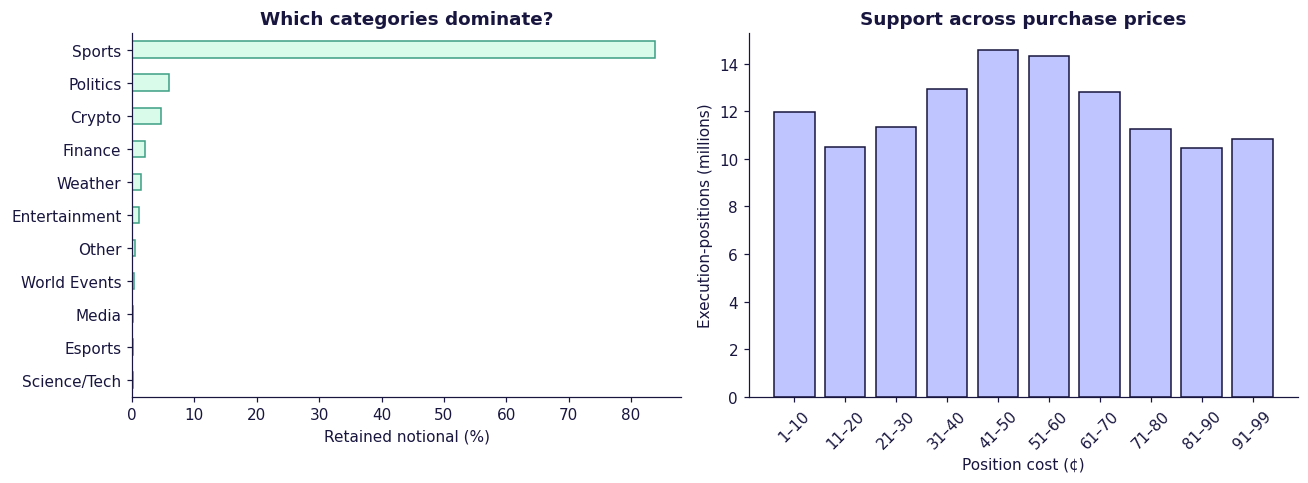

In [18]:
con.execute(
    """
    CREATE VIEW taker_positions AS
    SELECT t.ticker, m.event_id, c.category, t.quarter, t.n, t.units,
           t.taker_side AS direction,
           CASE WHEN t.taker_side = 'yes' THEN t.yes_price ELSE 100 - t.yes_price END AS cost,
           (t.taker_side = m.result)::INTEGER AS won
    FROM trade_cells t
    JOIN eligible_markets m USING (ticker)
    JOIN category_lookup c USING (series)
    """
)
con.execute(
    """
    CREATE VIEW positions AS
    SELECT *, 'Taker' AS role FROM taker_positions
    UNION ALL
    SELECT ticker, event_id, category, quarter, n, units,
           CASE WHEN direction = 'yes' THEN 'no' ELSE 'yes' END AS direction,
           100 - cost AS cost, 1 - won AS won, 'Maker' AS role
    FROM taker_positions
    """
)
con.execute(
    """
    CREATE VIEW measured_positions AS
    SELECT *, won - cost / 100.0 AS residual,
           (100.0 * won - cost) / cost AS roi,
           units * cost / 100.0 AS capital_usd
    FROM positions
    """
)
price_cells = con.sql(
    """
    SELECT role, direction, cost, sum(n)::BIGINT AS n, sum(n * won) AS wins,
           sum(units) AS units, sum(capital_usd) AS capital_usd,
           sum(units * residual) AS pnl_usd
    FROM measured_positions
    GROUP BY role, direction, cost ORDER BY role, direction, cost
    """
).df()
price_cells["win_rate"] = price_cells.wins / price_cells.n
price_cells["mispricing_pp"] = 100 * price_cells.win_rate - price_cells.cost
price_cells["roi_pct"] = 100 * price_cells.mispricing_pp / price_cells.cost
assert price_cells.n.sum() == 2 * population.retained_trades.iloc[0]
assert np.isclose(np.dot(price_cells.n, price_cells.mispricing_pp), 0, atol=1e-5)
assert np.isclose(price_cells.pnl_usd.sum(), 0, atol=1e-5)
price_cells.to_csv(OUTPUT / "price_role_direction.csv", index=False)

category_volume = con.sql(
    """
    SELECT c.category, sum(m.notional_usd) AS notional_usd, count(*) AS markets
    FROM eligible_markets m JOIN category_lookup c USING (series)
    GROUP BY c.category ORDER BY notional_usd DESC
    """
).df()
category_volume["notional_pct"] = 100 * category_volume.notional_usd / category_volume.notional_usd.sum()
price_coverage = price_cells.assign(decile=(price_cells.cost - 1) // 10).groupby("decile").n.sum()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
category_volume.sort_values("notional_pct").plot.barh(
    x="category", y="notional_pct", ax=axes[0], legend=False, color=PALETTE["mint"], edgecolor=PALETTE["mint_dark"]
)
axes[0].set(title="Which categories dominate?", xlabel="Retained notional (%)", ylabel="")
axes[1].bar(
    range(10),
    price_coverage.reindex(range(10), fill_value=0) / 1e6,
    color=PALETTE["lavender"],
    edgecolor=PALETTE["navy"],
)
axes[1].set_xticks(
    range(10), ["1–10", "11–20", "21–30", "31–40", "41–50", "51–60", "61–70", "71–80", "81–90", "91–99"], rotation=45
)
axes[1].set(title="Support across purchase prices", xlabel="Position cost (¢)", ylabel="Execution-positions (millions)")
show_figure("02_categories_and_price_coverage")
category_volume.to_csv(OUTPUT / "category_volume.csv", index=False)

**Read the charts:** category shares (Becker Figure 2) show which topics drive the sample. Unmatched series remain “Other.” The price bars (a coverage check like Figure 3) count **both positions per trade**, not unique trades. Large bars mean more executions, not necessarily more independent outcomes.

## 4. Are market prices calibrated?

A 5¢ position should win about 5% of the time. On the left, points below the diagonal win less often than their price suggests. On the right, the same gap is easier to see: negative values mean overpriced positions, and positive values mean underpriced positions. Becker's Figure 4 finds negative mispricing among longshots and positive mispricing among favorites.

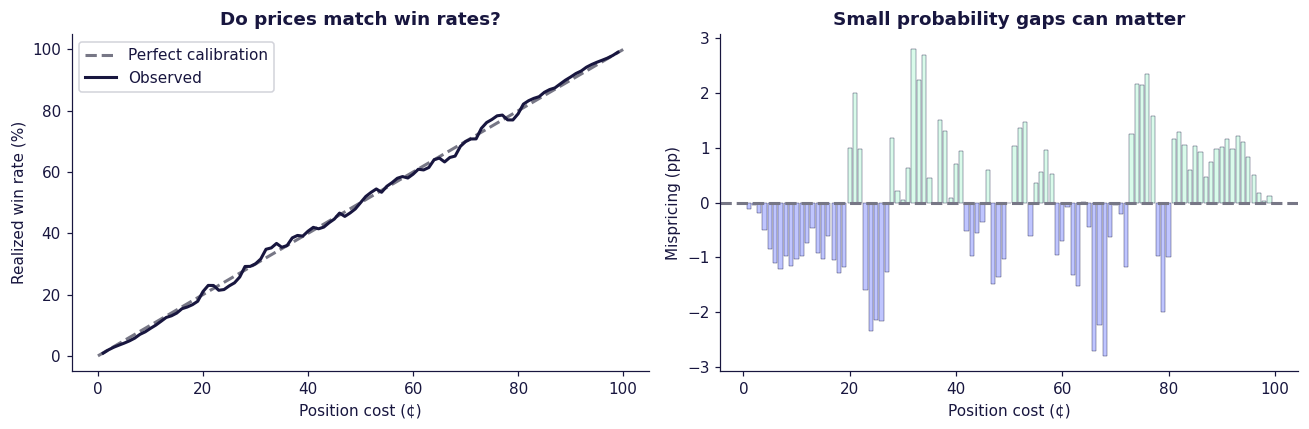

,cost,n,wins,win_pct,mispricing_pp,roi_pct
0,1,1909126,16899.0,0.885169,-0.114831,-11.483056
4,5,1183179,49236.0,4.161331,-0.838669,-16.773371
9,10,1126907,101152.0,8.976073,-1.023927,-10.239266
49,50,1638778,819389.0,50.000000,0.000000,0.000000
89,90,1126907,1025755.0,91.023927,1.023927,1.137696
94,95,1183179,1133943.0,95.838669,0.838669,0.882809
98,99,1909126,1892227.0,99.114831,0.114831,0.115990


In [19]:
calibration = price_cells.groupby("cost", as_index=False)[["n", "wins"]].sum()
calibration["win_pct"] = 100 * calibration.wins / calibration.n
calibration["mispricing_pp"] = calibration.win_pct - calibration.cost
calibration["roi_pct"] = 100 * calibration.mispricing_pp / calibration.cost

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot([0, 100], [0, 100], "--", color=PALETTE["gray_dark"], label="Perfect calibration")
axes[0].plot(calibration.cost, calibration.win_pct, color=PALETTE["navy"], label="Observed")
axes[0].set(title="Do prices match win rates?", xlabel="Position cost (¢)", ylabel="Realized win rate (%)")
axes[0].legend()
axes[1].bar(
    calibration.cost,
    calibration.mispricing_pp,
    color=np.where(calibration.mispricing_pp < 0, PALETTE["lavender"], PALETTE["mint"]),
    edgecolor=PALETTE["navy"],
    linewidth=0.25,
)
axes[1].axhline(0, color=PALETTE["gray_dark"], linestyle="--")
axes[1].set(title="Small probability gaps can matter", xlabel="Position cost (¢)", ylabel="Mispricing (pp)")
show_figure("03_calibration")
calibration.to_csv(OUTPUT / "calibration.csv", index=False)
save_table(calibration[calibration.cost.isin([1, 5, 10, 50, 90, 95, 99])], "calibration_examples")

## 5. Does the YES/NO wording matter?

Compare YES and NO positions that cost the **same amount**. Their possible payouts match, so a return gap is a useful descriptive check of Becker's YES/NO asymmetry (Figure 5). The longshot panel zooms in on 1–10¢, where dividing a small probability error by a small investment can produce a large ROI.

These curves combine different contracts. A gap alone does not show that wording causes the difference, or establish significance at each price.

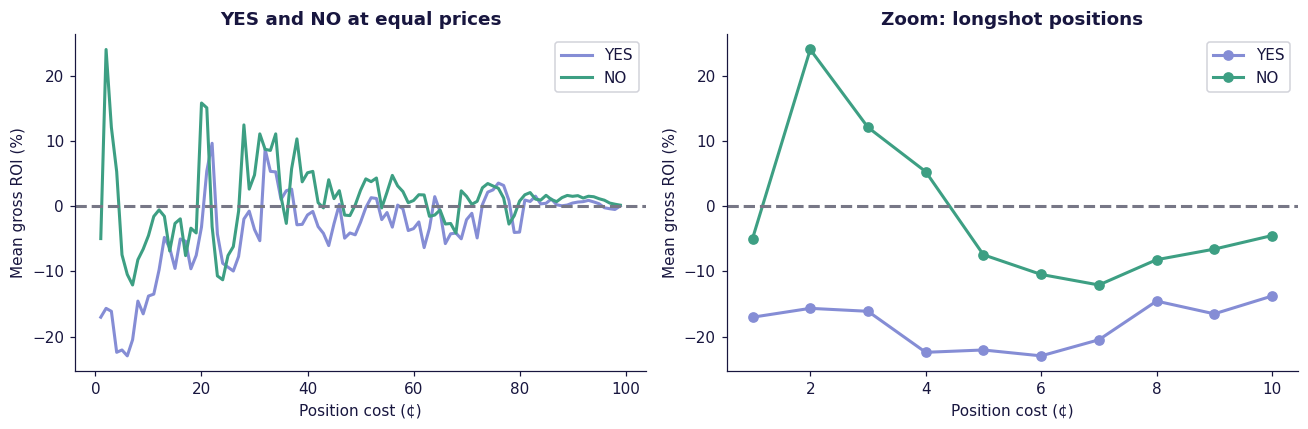

In [20]:
direction_rates = price_cells.groupby(["direction", "cost"], as_index=False)[["n", "wins"]].sum()
direction_rates["win_rate"] = direction_rates.wins / direction_rates.n
direction_rates["mispricing_pp"] = 100 * direction_rates.win_rate - direction_rates.cost
direction_rates["roi_pct"] = 100 * direction_rates.mispricing_pp / direction_rates.cost

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for direction, color in DIRECTION_COLORS.items():
    rows = direction_rates[direction_rates.direction.eq(direction)]
    axes[0].plot(rows.cost, rows.roi_pct, color=color, label=direction.upper())
    longshots = rows[rows.cost.le(10)]
    axes[1].plot(longshots.cost, longshots.roi_pct, "o-", color=color, label=direction.upper())
for ax in axes:
    ax.axhline(0, color=PALETTE["gray_dark"], linestyle="--")
    ax.set(xlabel="Position cost (¢)", ylabel="Mean gross ROI (%)")
    ax.legend()
axes[0].set_title("YES and NO at equal prices")
axes[1].set_title("Zoom: longshot positions")
show_figure("04_yes_no_returns")
direction_rates.to_csv(OUTPUT / "yes_no_returns.csv", index=False)

### Who supplies each side?

This is the capital-at-risk view from Becker's Figure 6. Each vertical slice adds to 100%. It shows whether makers or takers supply the dollars at each price and direction. Dollar shares count `units × own price`, rather than simply counting executions. A large share says who holds the exposure; it does not say whether that exposure was profitable.

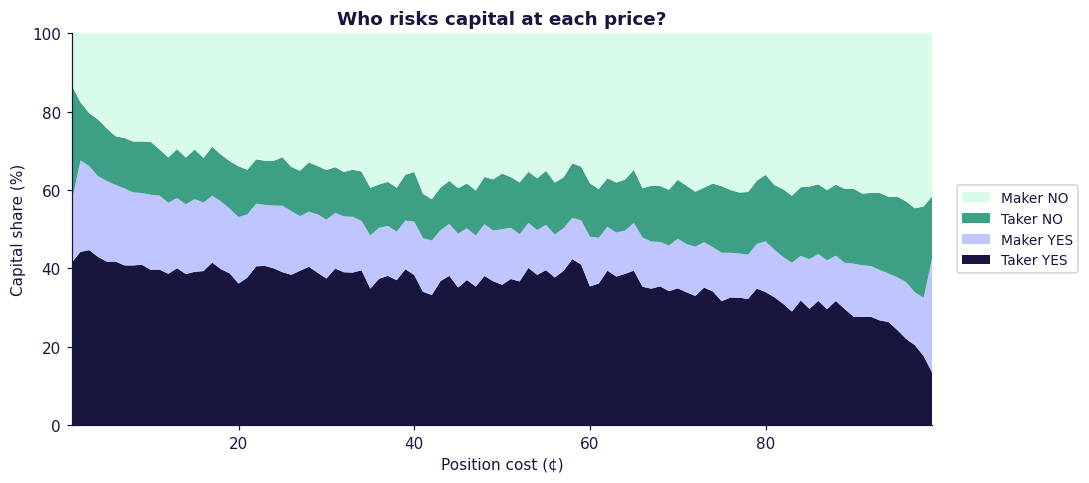

In [21]:
capital = price_cells.pivot(index="cost", columns=["role", "direction"], values="capital_usd").fillna(0)
capital = capital.reindex(columns=[("Taker", "yes"), ("Maker", "yes"), ("Taker", "no"), ("Maker", "no")])
capital_share = 100 * capital.div(capital.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.stackplot(
    capital_share.index,
    capital_share.T.to_numpy(),
    labels=["Taker YES", "Maker YES", "Taker NO", "Maker NO"],
    colors=[PALETTE["navy"], PALETTE["lavender"], PALETTE["mint_dark"], PALETTE["mint"]],
)
ax.set(
    title="Who risks capital at each price?",
    xlabel="Position cost (¢)",
    ylabel="Capital share (%)",
    xlim=(1, 99),
    ylim=(0, 100),
)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=9)
show_figure("05_capital_by_role_direction")
capital_share.to_csv(OUTPUT / "capital_share_by_price.csv")

## 6. Do makers and takers perform differently?

We compare roles at equal purchase prices (Becker Figures 7–8). Above zero means positive average ROI before fees. The second panel splits makers into YES and NO positions, so a maker advantage cannot hide a difference between the two directions. Buying NO is not automatically the same thing as being a maker.

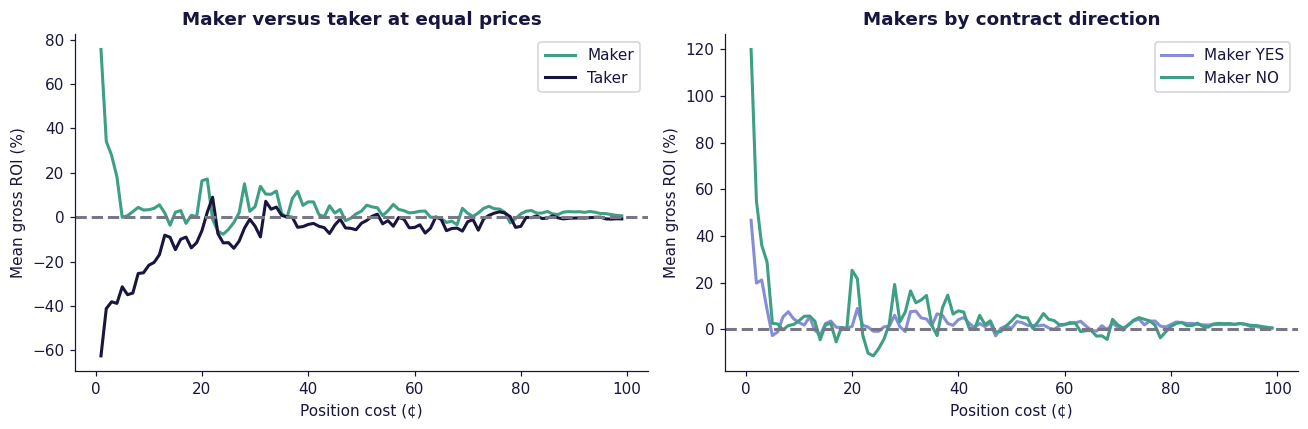

In [22]:
role_rates = price_cells.groupby(["role", "cost"], as_index=False)[["n", "wins"]].sum()
role_rates["mispricing_pp"] = 100 * role_rates.wins / role_rates.n - role_rates.cost
role_rates["roi_pct"] = 100 * role_rates.mispricing_pp / role_rates.cost

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for role, color in ROLE_COLORS.items():
    rows = role_rates[role_rates.role.eq(role)]
    axes[0].plot(rows.cost, rows.roi_pct, color=color, label=role)
for direction, color in DIRECTION_COLORS.items():
    rows = price_cells[price_cells.role.eq("Maker") & price_cells.direction.eq(direction)]
    axes[1].plot(rows.cost, rows.roi_pct, color=color, label=f"Maker {direction.upper()}")
for ax in axes:
    ax.axhline(0, color=PALETTE["gray_dark"], linestyle="--")
    ax.set(xlabel="Position cost (¢)", ylabel="Mean gross ROI (%)")
    ax.legend()
axes[0].set_title("Maker versus taker at equal prices")
axes[1].set_title("Makers by contract direction")
show_figure("06_role_returns")
role_rates.to_csv(OUTPUT / "role_returns_by_price.csv", index=False)

### Check uncertainty using related outcomes

Millions of executions do not mean millions of independent observations: trades in one market share an outcome. We calculate 95% normal-approximation intervals using **market clusters** and **event-family clusters**, following Becker's two levels. The maker-minus-taker comparison is paired within each cluster.

Mispricing and ROI appear as separate estimates. A mispricing gap can be precise even when the ROI gap is noisy, because cheap positions have large percentage returns. An interval crossing zero does not establish a difference at the 5% level. These are descriptive comparisons, with no multiple-testing adjustment.

,cluster_level,clusters,metric,comparison,estimate,se,ci_low,ci_high,p_value
0,Market,351452,Mispricing (pp),Maker,1.240774,0.345740,0.563123,1.918425,3.322702e-04
1,Market,351452,Mispricing (pp),Taker,-1.240774,0.345740,-1.918425,-0.563123,3.322702e-04
2,Market,351452,Mispricing (pp),Maker − Taker,2.481548,0.691480,1.126247,3.836850,3.322702e-04
3,Market,351452,Mean gross ROI (%),Maker,4.243546,0.928687,2.423319,6.063773,4.891170e-06
4,Market,351452,Mean gross ROI (%),Taker,-7.068472,1.151764,-9.325929,-4.811015,8.405003e-10
5,Market,351452,Mean gross ROI (%),Maker − Taker,11.312018,1.718822,7.943128,14.680908,4.664660e-11
6,Event family,100945,Mispricing (pp),Maker,1.240774,0.144436,0.957680,1.523869,8.660693e-18
7,Event family,100945,Mispricing (pp),Taker,-1.240774,0.144436,-1.523869,-0.957680,8.660693e-18
8,Event family,100945,Mispricing (pp),Maker − Taker,2.481548,0.288872,1.915359,3.047737,8.660693e-18
9,Event family,100945,Mean gross ROI (%),Maker,4.243546,0.799312,2.676894,5.810198,1.102296e-07


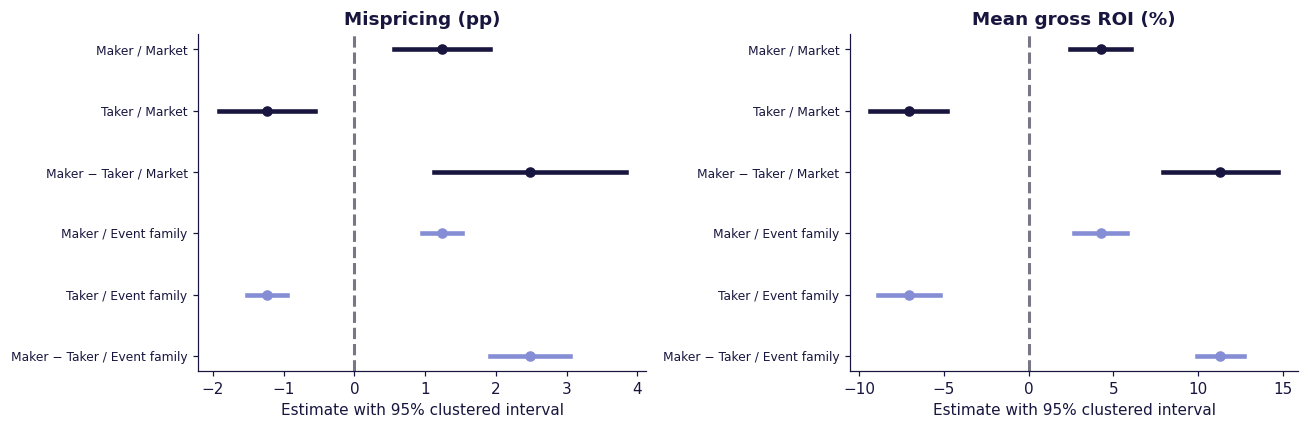

In [23]:
def clustered_role_estimates(blocks: pd.DataFrame, cluster_level: str) -> pd.DataFrame:
    """Estimate role means and their paired gap using cluster-sum influences."""
    counts = blocks.pivot(index="unit", columns="role", values="n").fillna(0)
    if len(counts) < 2:
        raise ValueError("Need at least two clusters for uncertainty estimates.")
    rows = []
    correction = len(counts) / (len(counts) - 1)
    for column, metric in [("residual_sum", "Mispricing (pp)"), ("roi_sum", "Mean gross ROI (%)")]:
        totals = blocks.pivot(index="unit", columns="role", values=column).fillna(0)
        means = totals.sum() / counts.sum()
        influences = (totals - counts.mul(means, axis=1)).div(counts.sum(), axis=1)
        estimates = {role: (means[role], influences[role]) for role in ["Maker", "Taker"]}
        estimates["Maker − Taker"] = (means["Maker"] - means["Taker"], influences.Maker - influences.Taker)
        for role, (mean, influence) in estimates.items():
            se = np.sqrt(correction * np.square(influence).sum())
            z = mean / se if se > 0 else np.nan
            rows.append(
                {
                    "cluster_level": cluster_level,
                    "clusters": len(counts),
                    "metric": metric,
                    "comparison": role,
                    "estimate": 100 * mean,
                    "se": 100 * se,
                    "ci_low": 100 * (mean - 1.96 * se),
                    "ci_high": 100 * (mean + 1.96 * se),
                    "p_value": 2 * norm.sf(abs(z)),
                }
            )
    return pd.DataFrame(rows)


inference_tables = []
for column, level in [("ticker", "Market"), ("event_id", "Event family")]:
    blocks = con.sql(
        f"""
        SELECT {column} AS unit, role, sum(n) AS n,
               sum(n * residual) AS residual_sum, sum(n * roi) AS roi_sum
        FROM measured_positions GROUP BY {column}, role
        """
    ).df()
    inference_tables.append(clustered_role_estimates(blocks, level))
inference = pd.concat(inference_tables, ignore_index=True)
save_table(inference, "clustered_role_estimates")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["Mispricing (pp)", "Mean gross ROI (%)"]):
    rows = inference[inference.metric.eq(metric)].reset_index(drop=True)
    for i, row in rows.iterrows():
        color = PALETTE["navy"] if row.cluster_level == "Market" else PALETTE["lavender_dark"]
        ax.plot([row.ci_low, row.ci_high], [i, i], color=color, linewidth=3)
        ax.scatter(row.estimate, i, color=color, s=35, zorder=3)
    ax.set_yticks(range(len(rows)), rows.comparison + " / " + rows.cluster_level, fontsize=8)
    ax.axvline(0, color=PALETTE["gray_dark"], linestyle="--")
    ax.invert_yaxis()
    ax.set(title=metric, xlabel="Estimate with 95% clustered interval")
show_figure("07_clustered_uncertainty")

## 7. Does the pattern vary over time or topic?

The first chart follows Becker's role-over-time check (Figure 9), displaying mispricing and ROI separately. The heatmap tracks taker capital across price bands (Figure 10); darker cells mean larger shares within a quarter. A larger low-price share means more taker dollars went into longshots, not that longshots became better investments. Our sample starts after the 2024 election, so it cannot test Becker's earlier maker–taker reversal.

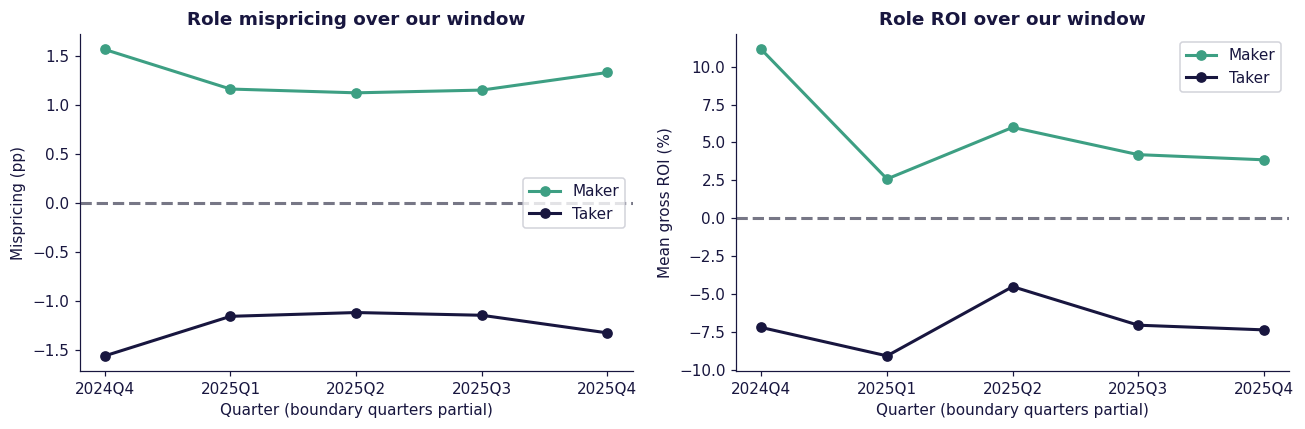

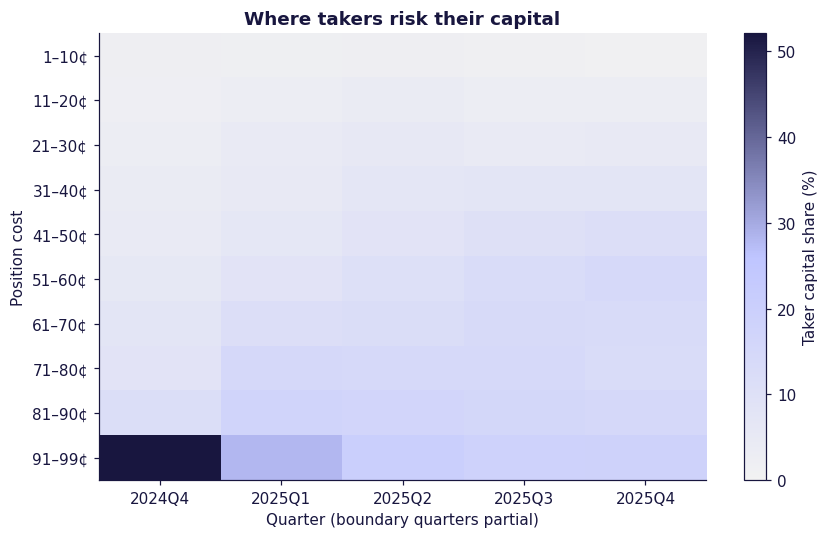

In [24]:
quarterly_roles = con.sql(
    """
    SELECT quarter, role, sum(n) AS n,
           100 * sum(n * residual) / sum(n) AS mispricing_pp,
           100 * sum(n * roi) / sum(n) AS roi_pct
    FROM measured_positions GROUP BY quarter, role ORDER BY quarter, role
    """
).df()
labels = quarterly_roles.quarter.dt.to_period("Q").astype(str)
quarterly_roles["quarter_label"] = labels
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for role, color in ROLE_COLORS.items():
    rows = quarterly_roles[quarterly_roles.role.eq(role)]
    for ax, column in zip(axes, ["mispricing_pp", "roi_pct"]):
        ax.plot(rows.quarter_label, rows[column], "o-", color=color, label=role)
for ax in axes:
    ax.axhline(0, color=PALETTE["gray_dark"], linestyle="--")
    ax.set_xlabel("Quarter (boundary quarters partial)")
    ax.legend()
axes[0].set(title="Role mispricing over our window", ylabel="Mispricing (pp)")
axes[1].set(title="Role ROI over our window", ylabel="Mean gross ROI (%)")
show_figure("08_roles_over_time")
quarterly_roles.to_csv(OUTPUT / "roles_over_time.csv", index=False)

price_bands = con.sql(
    """
    SELECT quarter, ((cost - 1) // 10)::INTEGER AS decile, sum(capital_usd) AS capital_usd
    FROM measured_positions WHERE role = 'Taker'
    GROUP BY quarter, decile ORDER BY quarter, decile
    """
).df()
band_capital = price_bands.pivot(index="quarter", columns="decile", values="capital_usd").fillna(0)
band_share = 100 * band_capital.div(band_capital.sum(axis=1), axis=0)
band_share.columns = [f"{10 * i + 1}–{min(10 * i + 10, 99)}¢" for i in band_share.columns]
band_share.index = band_share.index.to_period("Q").astype(str)
fig, ax = plt.subplots(figsize=(8, 5))
capital_cmap = LinearSegmentedColormap.from_list(
    "replication_capital", [PALETTE["gray_light"], PALETTE["lavender"], PALETTE["navy"]]
)
image = ax.imshow(band_share.T, aspect="auto", cmap=capital_cmap, vmin=0)
ax.set_xticks(range(len(band_share)), band_share.index)
ax.set_yticks(range(len(band_share.columns)), band_share.columns)
ax.set(
    title="Where takers risk their capital",
    xlabel="Quarter (boundary quarters partial)",
    ylabel="Position cost",
)
fig.colorbar(image, ax=ax, label="Taker capital share (%)")
show_figure("09_taker_price_bands")
band_share.to_csv(OUTPUT / "taker_capital_bands.csv")

### Compare broad categories

Becker's category comparison (Table 3) motivates this check. The left panel reports Equation 1; the right reports Equation 2, rather than treating the measures as interchangeable. Bars are descriptive averages, without category-specific significance tests. Category rules can leave some series unmatched, and category composition differs from Becker's full sample.

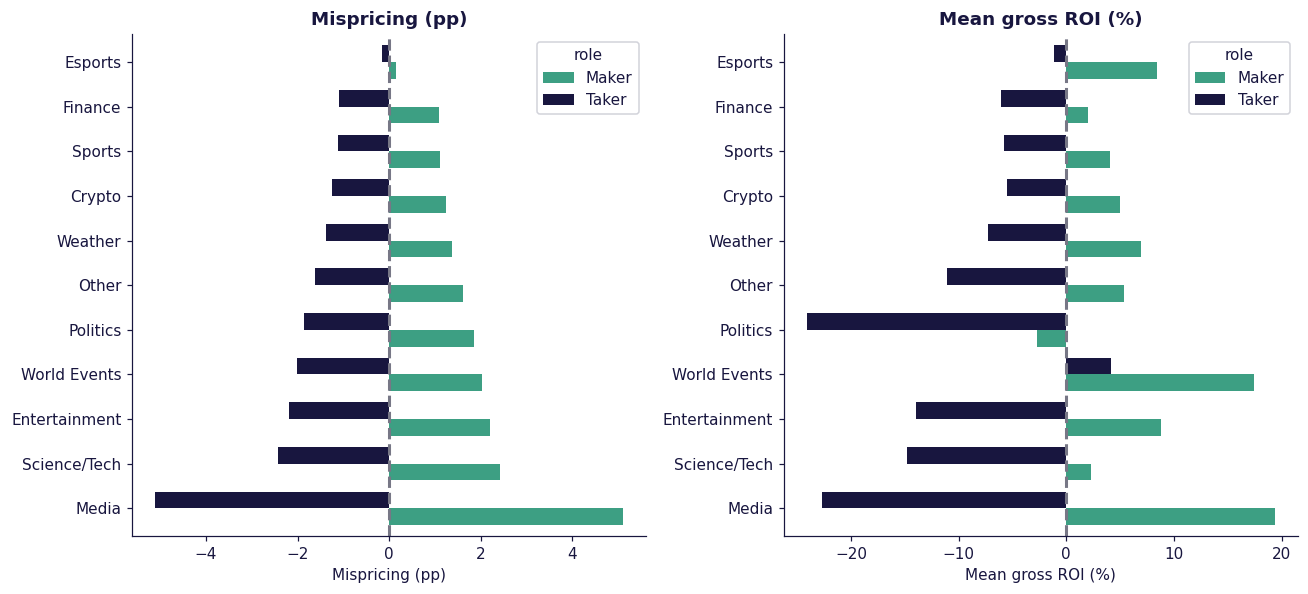

,category,role,n,mispricing_pp,roi_pct,capital_weighted_roi_pct
3,Crypto,Maker,6278488.0,1.250960,4.957831,1.821922
16,Crypto,Taker,6278488.0,-1.250960,-5.546882,-1.641923
19,Entertainment,Maker,1310792.0,2.191052,8.816340,2.421505
0,Entertainment,Taker,1310792.0,-2.191052,-13.946235,-3.393541
15,Esports,Maker,97910.0,0.156307,8.388978,-7.317637
6,Esports,Taker,97910.0,-0.156307,-1.096690,8.253160
8,Finance,Maker,1470637.0,1.094851,2.044077,1.822503
12,Finance,Taker,1470637.0,-1.094851,-6.047544,-1.782107
9,Media,Maker,387489.0,5.100774,19.350570,4.556124
13,Media,Taker,387489.0,-5.100774,-22.693098,-6.615953


In [25]:
category_roles = con.sql(
    """
    SELECT category, role, sum(n) AS n,
           100 * sum(n * residual) / sum(n) AS mispricing_pp,
           100 * sum(n * roi) / sum(n) AS roi_pct,
           100 * sum(units * residual) / sum(capital_usd) AS capital_weighted_roi_pct
    FROM measured_positions GROUP BY category, role
    """
).df()
category_order = category_roles[category_roles.role.eq("Taker")].sort_values("mispricing_pp").category
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, column, title in zip(axes, ["mispricing_pp", "roi_pct"], ["Mispricing (pp)", "Mean gross ROI (%)"]):
    table = category_roles.pivot(index="category", columns="role", values=column).reindex(category_order)
    table[["Maker", "Taker"]].plot.barh(ax=ax, color=[ROLE_COLORS["Maker"], ROLE_COLORS["Taker"]], width=0.75)
    ax.axvline(0, color=PALETTE["gray_dark"], linestyle="--")
    ax.set(title=title, xlabel=title, ylabel="")
show_figure("10_category_roles")
save_table(category_roles.sort_values(["category", "role"]), "category_roles")

## 8. Where does taker mispricing come from?

Becker's Equation 3 splits **mean mispricing**, not ROI, into three parts:

- **Price selection:** choosing prices where the pooled calibration error is higher or lower.
- **Direction selection:** choosing YES versus NO at each price.
- **Execution:** performing differently from the pooled positions at the same price and direction.

For each price, the pooled reference averages YES and NO equally; the direction term accounts for unequal selection between them. These components add exactly to the role's mean mispricing. This is an accounting decomposition, not a causal model. “Execution” here does not isolate spreads, fees, or trader skill.

,role,price_selection_pp,direction_selection_pp,execution_pp,total_pp
0,Maker,0.018154,0.301367,0.921253,1.240774
1,Taker,-0.018154,-0.301367,-0.921253,-1.240774


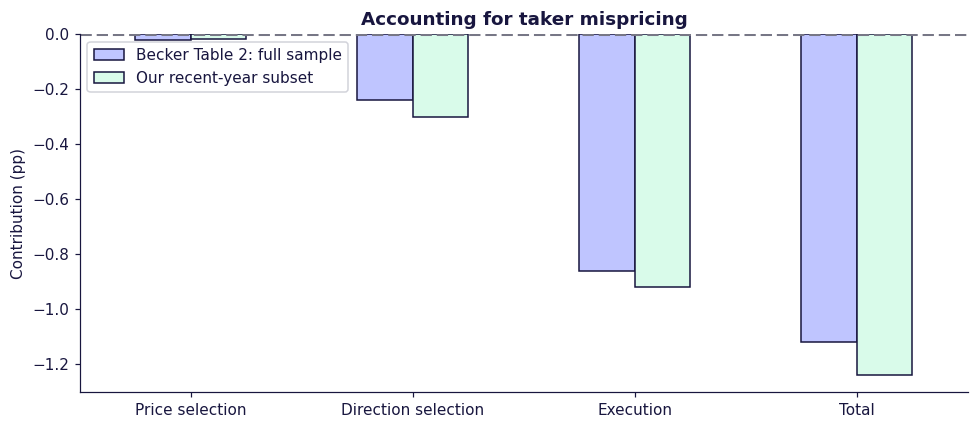

,component,paper_full_sample_pp,our_subset_pp
0,Price selection,-0.02,-0.018154
1,Direction selection,-0.24,-0.301367
2,Execution,-0.86,-0.921253
3,Total,-1.12,-1.240774


In [26]:
def decompose_mispricing(cells: pd.DataFrame) -> pd.DataFrame:
    """Apply Becker's price, direction, and execution decomposition (Equation 3)."""
    pooled = cells.groupby(["cost", "direction"], as_index=False)[["n", "wins"]].sum()
    pooled["pooled_win"] = pooled.wins / pooled.n
    pooled["delta"] = pooled.pooled_win - pooled.cost / 100
    reference = pooled.pivot(index="cost", columns="direction", values="delta")
    if reference[["yes", "no"]].isna().any().any():
        raise ValueError("Both directions must be observed at each reference price.")
    reference["price_reference"] = (reference.yes + reference.no) / 2
    reference["wedge"] = reference.yes - reference.no
    details = cells.merge(pooled[["cost", "direction", "pooled_win"]], on=["cost", "direction"])
    details = details.join(reference[["price_reference", "wedge"]], on="cost")
    rows = []
    for role, group in details.groupby("role"):
        weight = group.n / group.n.sum()
        price = np.dot(weight, group.price_reference)
        sign = np.where(group.direction.eq("yes"), 0.5, -0.5)
        direction = np.dot(weight, sign * group.wedge)
        execution = np.dot(weight, group.wins / group.n - group.pooled_win)
        total = np.dot(weight, group.wins / group.n - group.cost / 100)
        assert np.isclose(price + direction + execution, total, atol=1e-12)
        rows.append(
            {
                "role": role,
                "price_selection_pp": 100 * price,
                "direction_selection_pp": 100 * direction,
                "execution_pp": 100 * execution,
                "total_pp": 100 * total,
            }
        )
    return pd.DataFrame(rows)


decomposition = decompose_mispricing(price_cells)
save_table(decomposition, "mispricing_decomposition")
taker_decomposition = decomposition.set_index("role").loc["Taker"]
paper_decomposition = pd.DataFrame(
    {
        "component": ["Price selection", "Direction selection", "Execution", "Total"],
        "paper_full_sample_pp": [-0.02, -0.24, -0.86, -1.12],
        "our_subset_pp": taker_decomposition.to_numpy(),
    }
)
fig, ax = plt.subplots(figsize=(9, 4))
paper_decomposition.set_index("component").rename(
    columns={"paper_full_sample_pp": "Becker Table 2: full sample", "our_subset_pp": "Our recent-year subset"}
).plot.bar(ax=ax, color=[PALETTE["lavender"], PALETTE["mint"]], edgecolor=PALETTE["navy"], rot=0)
ax.axhline(0, color=PALETTE["gray_dark"], linestyle="--")
ax.set(title="Accounting for taker mispricing", xlabel="", ylabel="Contribution (pp)")
show_figure("11_taker_decomposition")
save_table(paper_decomposition, "paper_decomposition_comparison")

## 9. What replicated in this sample?

The table compares a few clearly defined results with Becker's reported numbers. Differences are expected: the time window, eligible markets, category mix, and observed-volume threshold differ. These are comparisons of estimates, not tests that our values equal the paper's values.

Use the clustered intervals above for the overall role comparison. The price-level curves and category bars are descriptive; they do not by themselves establish significance at every price or in every category. Positive gross ROI also does not imply an implementable trading strategy: we have no historical quotes, queue positions, or fee-adjusted execution model.

In [27]:
calibration_index = calibration.set_index("cost")
direction_index = direction_rates.set_index(["direction", "cost"])
comparison = pd.DataFrame(
    {
        "quantity": [
            "5¢ win rate (%)",
            "5¢ mispricing (pp)",
            "5¢ mean gross ROI (%)",
            "95¢ win rate (%)",
            "1¢ YES mean gross ROI (%)",
            "1¢ NO mean gross ROI (%)",
            "Taker mean mispricing (pp; Table 2)",
        ],
        "becker_full_sample": [4.18, -0.82, -16.4, 95.83, -41, 23, -1.12],
        "our_subset": [
            calibration_index.at[5, "win_pct"],
            calibration_index.at[5, "mispricing_pp"],
            calibration_index.at[5, "roi_pct"],
            calibration_index.at[95, "win_pct"],
            direction_index.at[("yes", 1), "roi_pct"],
            direction_index.at[("no", 1), "roi_pct"],
            taker_decomposition.total_pp,
        ],
    }
)
save_table(comparison, "paper_reference_comparison")
no_vs_yes = direction_rates.pivot(index="cost", columns="direction", values="roi_pct")
no_better = int((no_vs_yes.no > no_vs_yes.yes).sum())
role_gap = inference[inference.comparison.eq("Maker − Taker") & inference.metric.eq("Mispricing (pp)")]
longshot_negative = int((calibration.loc[calibration.cost.lt(20), "mispricing_pp"] < 0).sum())
favorite_positive = int((calibration.loc[calibration.cost.gt(80), "mispricing_pp"] > 0).sum())
lines = [
    f"**Our sample:** {int(population.retained_markets.iloc[0]):,} markets and {int(population.retained_trades.iloc[0]):,} trades.",
    f"At 5¢, positions won **{calibration_index.at[5, 'win_pct']:.2f}%** of the time: **{calibration_index.at[5, 'mispricing_pp']:+.2f} pp** mispricing and **{calibration_index.at[5, 'roi_pct']:+.1f}%** mean gross ROI.",
    f"Mispricing was negative at **{longshot_negative} of 19** prices below 20¢ and positive at **{favorite_positive} of 19** prices above 80¢, matching Becker's tail pattern when both counts are 19.",
    f"NO had higher mean ROI at **{no_better} of {len(no_vs_yes)}** price levels (Becker reports 69 of 99).",
]
for row in role_gap.itertuples():
    evidence = "excludes zero" if row.ci_low > 0 or row.ci_high < 0 else "includes zero"
    lines.append(
        f"With {row.cluster_level.lower()} clusters, the maker-minus-taker mispricing gap was **{row.estimate:+.2f} pp**, 95% interval **[{row.ci_low:+.2f}, {row.ci_high:+.2f}]**; it {evidence}."
    )
lines.append(
    f"The 1¢ NO estimate was **{direction_index.at[('no', 1), 'roi_pct']:+.1f}%** ROI, compared with Becker's **+23%**. Check this comparison alongside the tail pattern: reproducing the broad result does not mean every price-level estimate matches."
)
lines.append(
    "This establishes the descriptive starting point for our extension. The extension asks whether finer group assignments help predict these deviations out of sample; it is a separate question from whether mispricing exists."
)
display(Markdown("\n\n".join(lines)))

,quantity,becker_full_sample,our_subset
0,5¢ win rate (%),4.18,4.161331
1,5¢ mispricing (pp),-0.82,-0.838669
2,5¢ mean gross ROI (%),-16.40,-16.773371
3,95¢ win rate (%),95.83,95.838669
4,1¢ YES mean gross ROI (%),-41.00,-17.033972
5,1¢ NO mean gross ROI (%),23.00,-4.960467
6,Taker mean mispricing (pp; Table 2),-1.12,-1.240774


**Our sample:** 351,452 markets and 60,451,460 trades.

At 5¢, positions won **4.16%** of the time: **-0.84 pp** mispricing and **-16.8%** mean gross ROI.

Mispricing was negative at **19 of 19** prices below 20¢ and positive at **19 of 19** prices above 80¢, matching Becker's tail pattern when both counts are 19.

NO had higher mean ROI at **85 of 99** price levels (Becker reports 69 of 99).

With market clusters, the maker-minus-taker mispricing gap was **+2.48 pp**, 95% interval **[+1.13, +3.84]**; it excludes zero.

With event family clusters, the maker-minus-taker mispricing gap was **+2.48 pp**, 95% interval **[+1.92, +3.05]**; it excludes zero.

The 1¢ NO estimate was **-5.0%** ROI, compared with Becker's **+23%**. Check this comparison alongside the tail pattern: reproducing the broad result does not mean every price-level estimate matches.

This establishes the descriptive starting point for our extension. The extension asks whether finer group assignments help predict these deviations out of sample; it is a separate question from whether mispricing exists.

### Scope and sources

- **Paper:** Jonathan Becker, *The Microstructure of Wealth Transfer in Prediction Markets*, July 2026 version (first version January 18, 2026). Equations 1–3, Figures 1–10, and Tables 1–3 guide these checks. The supplied PDF is `Paper 1.pdf` in the course's Week 1/Papers folder.
- **Data:** master CSVs and the window recorded in `data/kalshi_recent_year_csv/manifest.json`. Event IDs use `event_ticker`, with a market-ticker fallback when missing. These are event-family proxies; they need not absorb every dependency across events.
- **Implementation choices:** valid 1–99¢ executions, binary finalized outcomes, and at least $100 observed-window notional. Both positions are included. No extension-specific clustering screens, predictive models, or fee adjustments.
- **Metric labels:** Equation 1 is always labeled mispricing (pp); Equation 2 is always labeled ROI (%). This avoids ambiguity where inherited repository analyses call probability residuals “excess returns.” We compare the overall mispricing number with the explicitly labeled decomposition in paper Table 2.

The final cell records inputs, software versions, and source hashes. Running all cells rebuilds every table and all 11 figures; no outputs from `main.ipynb` are required.

In [28]:
notebook_path = ROOT / "extension/notebooks/replication.ipynb"
notebook = json.loads(notebook_path.read_text())
authored = [(cell["cell_type"], "".join(cell["source"])) for cell in notebook["cells"]]
manifest = {
    "completed": True,
    "sample_window": {key: source_manifest[key] for key in ["window_start_inclusive", "window_end_inclusive"]},
    "population": population.iloc[0].to_dict(),
    "invalid_trades": int(trade_audit.invalid_trades.iloc[0]),
    "minimum_observed_notional_usd": 100,
    "weighting": "Equal execution-position weights for means; units times cost for capital shares",
    "cluster_levels": ["market ticker", "event_ticker with ticker fallback"],
    "inputs": [
        {"path": str(path.relative_to(ROOT)), "bytes": path.stat().st_size, "mtime_ns": path.stat().st_mtime_ns}
        for path in INPUTS
    ],
    "category_source_sha256": hashlib.sha256(CATEGORY_SOURCE.read_bytes()).hexdigest(),
    "notebook_sha256": hashlib.sha256(json.dumps(authored).encode()).hexdigest(),
    "versions": {package: version(package) for package in ["duckdb", "numpy", "pandas", "scipy", "matplotlib"]},
    "chart_palette": PALETTE,
    "elapsed_seconds": time.time() - started,
}
(OUTPUT / "run_manifest.json").write_text(json.dumps(manifest, indent=2) + "\n")
con.close()
print(f"Completed in {manifest['elapsed_seconds'] / 60:.1f} minutes. Tables and 11 figures: {OUTPUT}")

Completed in 0.7 minutes. Tables and 11 figures: /Users/colekvasnak/Documents/School/DS 340W/prediction-market-analysis/output/replication
